# 3. Análisis exploratorio de datos (EDA) y visualizaciones

En este cuaderno analizo los datos limpios para responder a las preguntas principales del proyecto:
1. ¿Cuál es el perfil del cliente que más contrata el depósito a plazo fijo? (edad, trabajo, educación).
2. ¿Qué factores comerciales influyen más? (canal móvil vs fijo, si ya era cliente contactado antes, número de llamadas).
3. ¿Cómo influyen las variables macroeconómicas como el Euribor en la decisión de contratar?


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv('../data/processed/bank_cleaned.csv')
df['target_num'] = (df['y'] == 'yes').astype(int)

print(f"Dataset cargado con {df.shape[0]} filas y {df.shape[1]} columnas.")
df.head(2)


Dataset cargado con 43000 filas y 34 columnas.


,age,job,marital,education,default,housing,loan,contact,duration,campaign,...,kidhome,teenhome,dt_customer,numwebvisitsmonth,contact_month,contact_year,total_children,previously_contacted,age_group,target_num
0,45,housemaid,married,basic.4y,0,0,0,telephone,261,1,...,1,0,2012-04-04,29,8.0,2019.0,1,0,45-59,0
1,57,services,married,high.school,-1,0,0,telephone,149,1,...,1,1,2012-12-30,7,9.0,2016.0,2,0,45-59,0


### 3.1. Tasa global de conversión
Calculamos la proporción de clientes que han dicho que sí al depósito sobre el total de llamadas.


C:\Users\Jose\AppData\Local\Temp\ipykernel_28824\2423641371.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=ax[0], palette=['#4A90E2', '#50E3C2'])


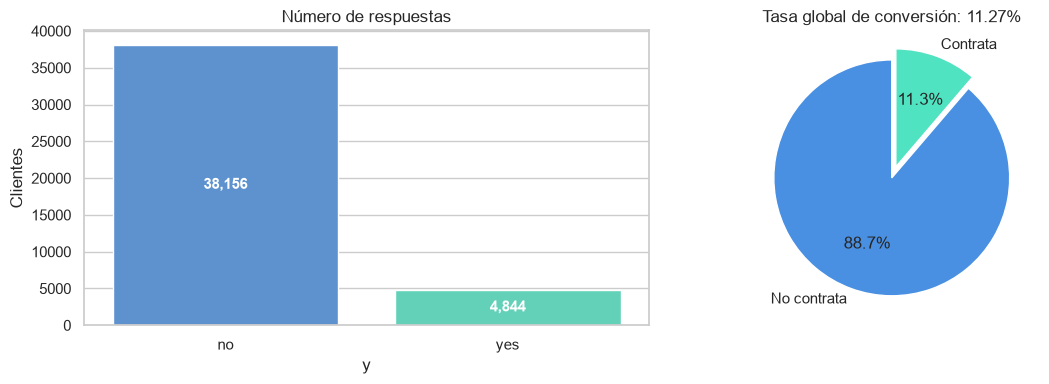

Tasa global: 11.27%


In [11]:
conversion_rate = df['target_num'].mean() * 100
counts = df['y'].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x=counts.index, y=counts.values, ax=ax[0], palette=['#4A90E2', '#50E3C2'])
ax[0].set_title('Número de respuestas')
ax[0].set_ylabel('Clientes')
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold', fontsize=11)

ax[1].pie(counts.values, labels=['No contrata', 'Contrata'],
          autopct='%1.1f%%', colors=['#4A90E2', '#50E3C2'], startangle=90, explode=(0, 0.1))
ax[1].set_title(f'Tasa global de conversión: {conversion_rate:.2f}%')

plt.tight_layout()
plt.show()

print(f"Tasa global: {conversion_rate:.2f}%")


### 3.2. Perfil sociodemográfico

#### A. Edad
Comparamos la tasa de conversión por grupo de edad y la distribución continua.


C:\Users\Jose\AppData\Local\Temp\ipykernel_28824\3746205202.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_conv.index, y=age_conv.values, ax=ax[0], palette='Blues_d')


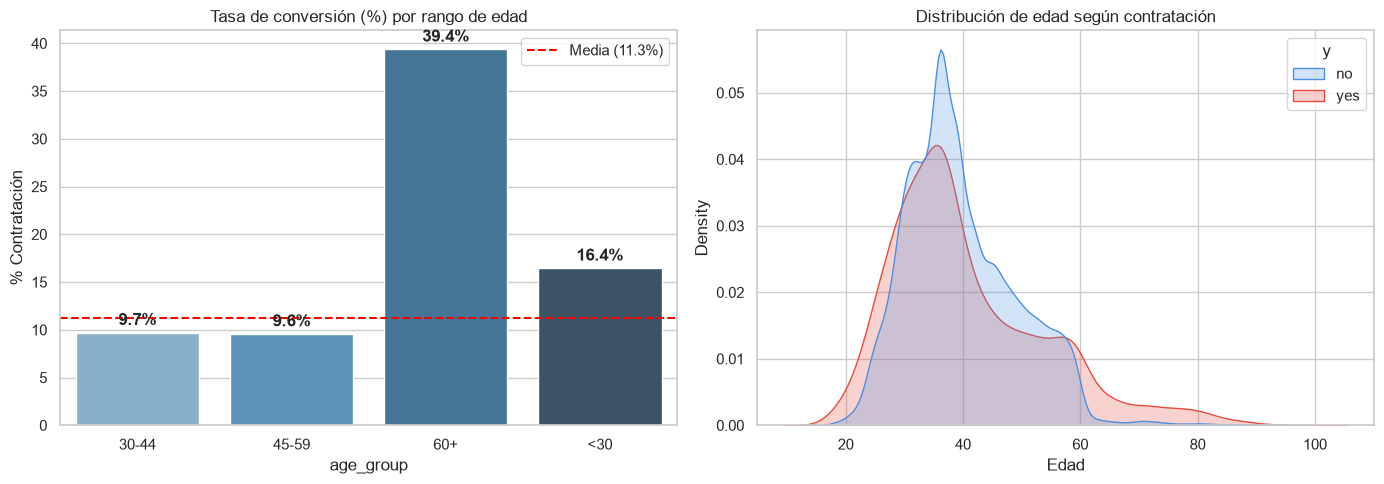

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

age_conv = df.groupby('age_group', observed=False)['target_num'].mean() * 100
sns.barplot(x=age_conv.index, y=age_conv.values, ax=ax[0], palette='Blues_d')
ax[0].set_title('Tasa de conversión (%) por rango de edad')
ax[0].set_ylabel('% Contratación')
ax[0].axhline(conversion_rate, color='red', linestyle='--', label=f'Media ({conversion_rate:.1f}%)')
ax[0].legend()
for p in ax[0].patches:
    ax[0].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='bottom', fontweight='bold', xytext=(0, 3), textcoords='offset points')

sns.kdeplot(data=df, x='age', hue='y', common_norm=False, fill=True, ax=ax[1], palette=['#4A90E2', '#E74C3C'])
ax[1].set_title('Distribución de edad según contratación')
ax[1].set_xlabel('Edad')

plt.tight_layout()
plt.show()


Los mayores de 60 años destacan con una tasa de contratación muy alta (casi el 40%). Los menores de 30 también están por encima de la media (16.4%), mientras que la franja entre 30 y 59 años se queda por debajo del 10%.


#### B. Profesión (`job`)
Calculamos el porcentaje de éxito según la ocupación del cliente.


C:\Users\Jose\AppData\Local\Temp\ipykernel_28824\1100138900.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(data=job_analysis, x='job', y='conversion_%', palette='viridis')


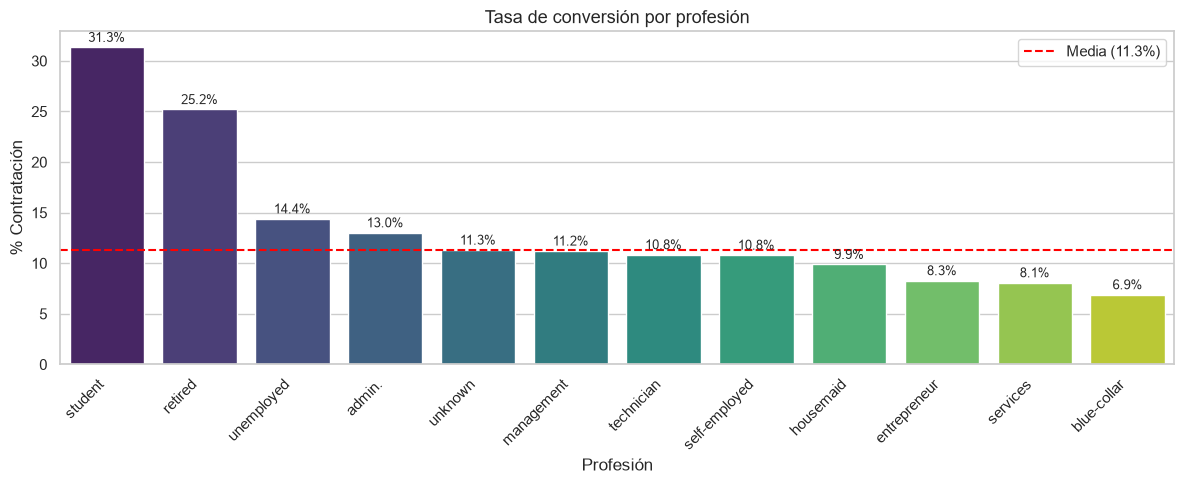

In [13]:
job_analysis = df.groupby('job')['target_num'].agg(['count', 'mean']).reset_index()
job_analysis['conversion_%'] = job_analysis['mean'] * 100
job_analysis = job_analysis.sort_values(by='conversion_%', ascending=False)

plt.figure(figsize=(12, 5))
barplot = sns.barplot(data=job_analysis, x='job', y='conversion_%', palette='viridis')
plt.title('Tasa de conversión por profesión', fontsize=13)
plt.xlabel('Profesión')
plt.ylabel('% Contratación')
plt.xticks(rotation=45, ha='right')
plt.axhline(conversion_rate, color='red', linestyle='--', label=f'Media ({conversion_rate:.1f}%)')
plt.legend()

for p in barplot.patches:
    barplot.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.show()


Estudiantes (31.3%) y jubilados (25.2%) son los que más contratan. En cambio, a los trabajadores del sector 'blue-collar' se les llama mucho pero tienen la tasa más baja (6.9%).


#### C. Educación y estado civil


C:\Users\Jose\AppData\Local\Temp\ipykernel_28824\4064153126.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=edu_conv.values, y=edu_conv.index, ax=ax[0], palette='Blues_r')
C:\Users\Jose\AppData\Local\Temp\ipykernel_28824\4064153126.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=marital_conv.index, y=marital_conv.values, ax=ax[1], palette='Purples_r')


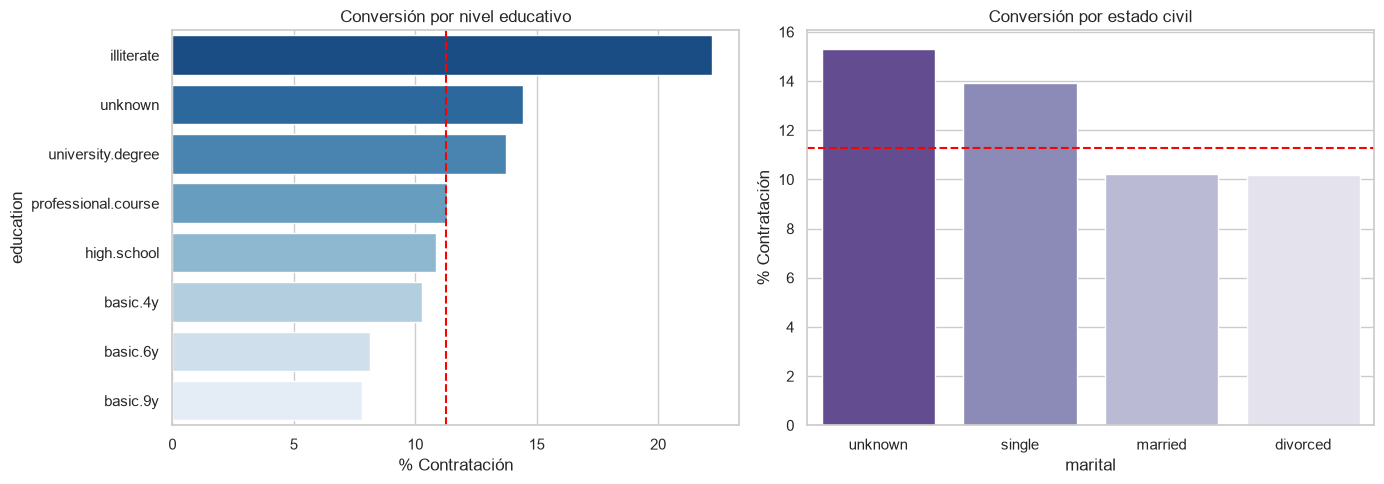

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

edu_conv = df.groupby('education')['target_num'].mean().sort_values(ascending=False) * 100
sns.barplot(x=edu_conv.values, y=edu_conv.index, ax=ax[0], palette='Blues_r')
ax[0].set_title('Conversión por nivel educativo')
ax[0].set_xlabel('% Contratación')
ax[0].axvline(conversion_rate, color='red', linestyle='--')

marital_conv = df.groupby('marital')['target_num'].mean().sort_values(ascending=False) * 100
sns.barplot(x=marital_conv.index, y=marital_conv.values, ax=ax[1], palette='Purples_r')
ax[1].set_title('Conversión por estado civil')
ax[1].set_ylabel('% Contratación')
ax[1].axhline(conversion_rate, color='red', linestyle='--')

plt.tight_layout()
plt.show()


### 3.3. Factores de la campaña comercial

#### A. Canal de contacto y clientes previamente contactados


C:\Users\Jose\AppData\Local\Temp\ipykernel_28824\3309144730.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=contact_conv.index, y=contact_conv.values, ax=ax[0], palette=['#3498DB', '#E67E22'])
C:\Users\Jose\AppData\Local\Temp\ipykernel_28824\3309144730.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Primer contacto', 'Ya contactado antes'], y=prev_conv.values, ax=ax[1], palette=['#95A5A6', '#2ECC71'])


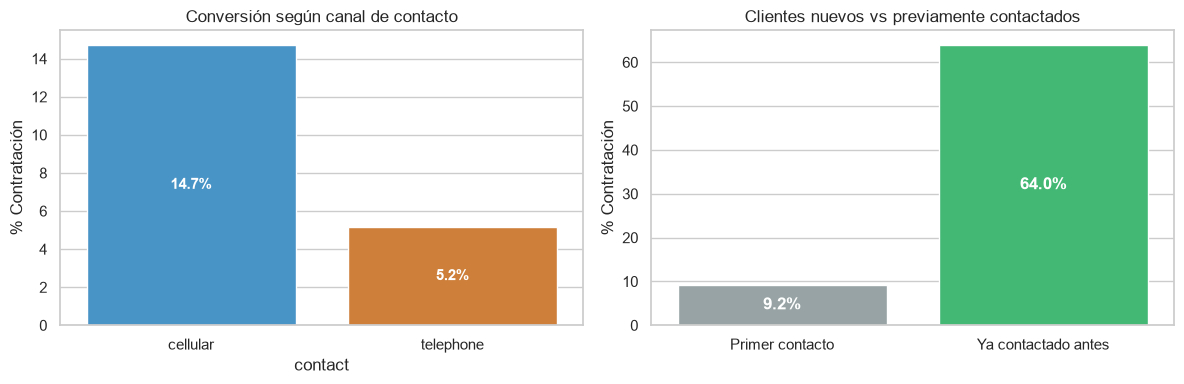

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

contact_conv = df.groupby('contact')['target_num'].mean() * 100
sns.barplot(x=contact_conv.index, y=contact_conv.values, ax=ax[0], palette=['#3498DB', '#E67E22'])
ax[0].set_title('Conversión según canal de contacto')
ax[0].set_ylabel('% Contratación')
for p in ax[0].patches:
    ax[0].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold', fontsize=11)

prev_conv = df.groupby('previously_contacted')['target_num'].mean() * 100
sns.barplot(x=['Primer contacto', 'Ya contactado antes'], y=prev_conv.values, ax=ax[1], palette=['#95A5A6', '#2ECC71'])
ax[1].set_title('Clientes nuevos vs previamente contactados')
ax[1].set_ylabel('% Contratación')
for p in ax[1].patches:
    ax[1].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()


El canal móvil funciona casi 3 veces mejor que el fijo. Además, si el cliente ya había sido contactado en campañas anteriores, la conversión pasa del 9.2% al 64.0%.


#### B. Número de llamadas en la campaña (`campaign`)
Comprobamos si insistir muchas veces al mismo cliente da resultados.


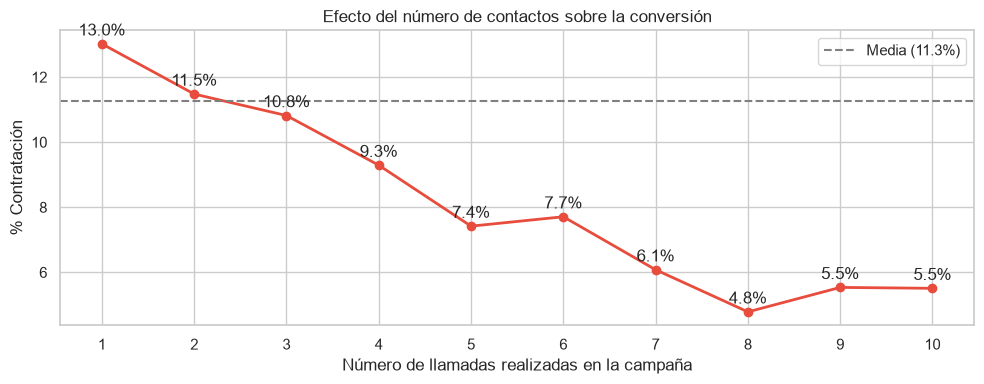

In [16]:
campaign_effect = df[df['campaign'] <= 10].groupby('campaign')['target_num'].agg(['count', 'mean'])
campaign_effect['conversion_%'] = campaign_effect['mean'] * 100

plt.figure(figsize=(10, 4))
plt.plot(campaign_effect.index, campaign_effect['conversion_%'], marker='o', linewidth=2, color='#E74C3C')
plt.title('Efecto del número de contactos sobre la conversión', fontsize=12)
plt.xlabel('Número de llamadas realizadas en la campaña')
plt.ylabel('% Contratación')
plt.xticks(campaign_effect.index)
plt.axhline(conversion_rate, color='gray', linestyle='--', label=f'Media ({conversion_rate:.1f}%)')
plt.legend()

for x, y_val in zip(campaign_effect.index, campaign_effect['conversion_%']):
    plt.annotate(f'{y_val:.1f}%', (x, y_val), textcoords='offset points', xytext=(0, 6), ha='center')

plt.tight_layout()
plt.show()


A partir de la tercera llamada la conversión cae por debajo de la media, y a partir de 5 llamadas no llega al 7%.


### 3.4. Factores macroeconómicos

#### A. Correlaciones con el target


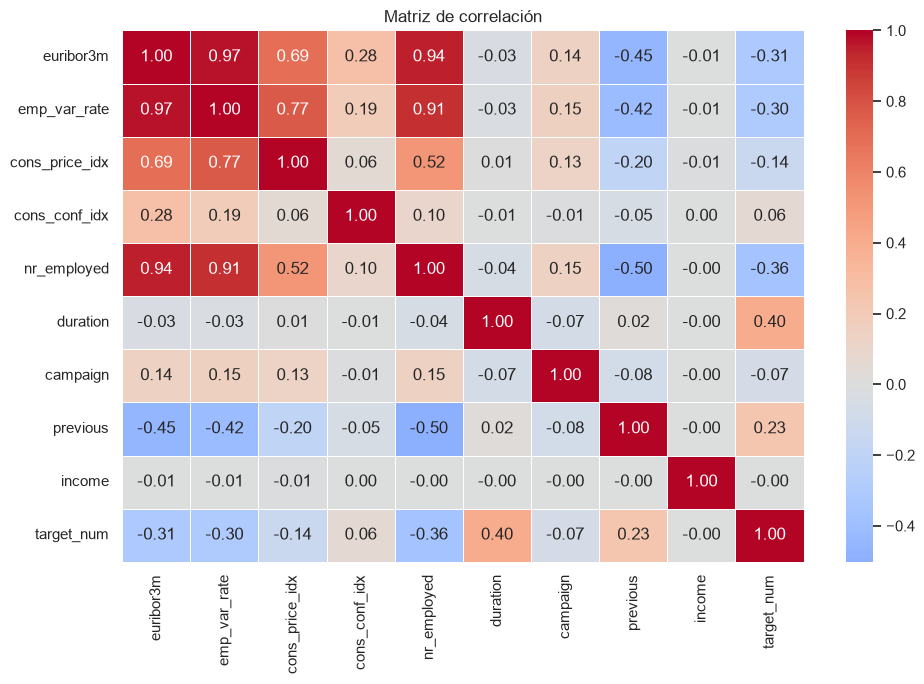

In [17]:
macro_cols = ['euribor3m', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'nr_employed',
              'duration', 'campaign', 'previous', 'income', 'target_num']

corr_matrix = df[macro_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()


#### B. Nivel de Euribor a 3 meses
Dividimos el Euribor en 4 tramos para ver cómo influye el entorno de tipos de interés.


C:\Users\Jose\AppData\Local\Temp\ipykernel_28824\3014921513.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=euribor_conv.index, y=euribor_conv.values, palette='RdYlGn_r')


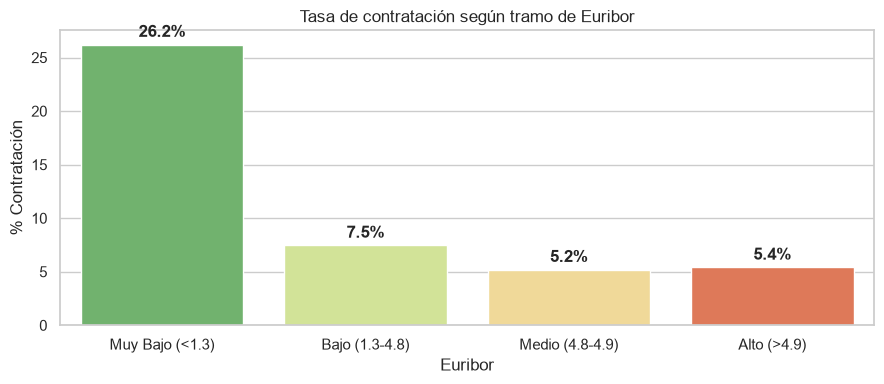

In [18]:
df['euribor_range'] = pd.qcut(df['euribor3m'], q=4, labels=['Muy Bajo (<1.3)', 'Bajo (1.3-4.8)', 'Medio (4.8-4.9)', 'Alto (>4.9)'])

euribor_conv = df.groupby('euribor_range', observed=False)['target_num'].mean() * 100

plt.figure(figsize=(9, 4))
sns.barplot(x=euribor_conv.index, y=euribor_conv.values, palette='RdYlGn_r')
plt.title('Tasa de contratación según tramo de Euribor', fontsize=12)
plt.ylabel('% Contratación')
plt.xlabel('Euribor')
for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='bottom', fontweight='bold', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


Con tipos de interés bajos, los clientes contratan notablemente más depósitos garantizados (en torno al 24%).
